In [1]:
import sys
import pickle
from pathlib import Path

import pandas as pd
import geopandas as gpd 
import numpy as np
import matplotlib as mp
import matplotlib.pyplot as plt

import config, data, models, train, evaluate

In [2]:
save_dir = Path("/nas/cee-water/cjgleason/ted/swot-ml/data/multigraph_manual")
metadata_dir = save_dir / "metadata"

subbasins = pd.read_parquet(metadata_dir / 'subbasins.parquet', columns=['site_id', 'uparea_km2', 'is_gauge', 'outlet_id'])
subbasins.index = subbasins.index.astype(str)

In [3]:
exp_root = Path("/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_MS_pooled")
target = 'discharge'

exp_dirs = [p.parent for p in (exp_root).rglob('results/test_results.parquet')] # dirs with test_data.pkl
exp_dirs

[PosixPath('/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_MS_pooled/era5_20260401_170510/results'),
 PosixPath('/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_MS_pooled/swot_s2_grace_20260401_202425/results'),
 PosixPath('/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_MS_pooled/swot_20260401_204203/results')]

In [3]:
exp_root =  Path("/nas/cee-water/cjgleason/ted/swot-ml/runs/rgcn")
target = 'discharge'

exp_dirs = [
    "/nas/cee-water/cjgleason/ted/swot-ml/runs/rgcn/era5_mlp_20260323_160231",
    "/nas/cee-water/cjgleason/ted/swot-ml/runs/rgcn/swot_mlp_20260323_155932",
]
exp_dirs = [Path(d) / 'results' for d in exp_dirs]
exp_dirs

[PosixPath('/nas/cee-water/cjgleason/ted/swot-ml/runs/rgcn/era5_mlp_20260323_160231/results'),
 PosixPath('/nas/cee-water/cjgleason/ted/swot-ml/runs/rgcn/swot_mlp_20260323_155932/results')]

In [4]:
def calc_discharge(df, subs):
    uparea = subs['uparea_km2'] 
    mapped_uparea = df.index.get_level_values('subbasin').map(uparea)
    
    df[('pred', 'discharge')] = df[('pred','unit_discharge')] * mapped_uparea
    df[('obs', 'discharge')] = df[('obs','unit_discharge')] * mapped_uparea
    return df

In [4]:
fig_dir = exp_root / "_figures"
fig_dir.mkdir(exist_ok=True, parents=True)

from tqdm import tqdm
import evaluate

exps = []
for exp_dir in tqdm(exp_dirs):
    try:
        exp_name = ' '.join(exp_dir.parent.stem.split('_')[:-2])
        
        results = pd.read_parquet(exp_dir / 'test_results.parquet').dropna()

        if 'unit_discharge' in results['pred'].columns:
            results = calc_discharge(results, subbasins)

        # bulk_m = evaluate.get_all_metrics(results)
        # basin_m = evaluate.get_basin_metrics(results)

        with open(exp_dir / "test_metrics.pkl", 'rb') as f:
            bulk_m, basin_m = pickle.load(f)
        
        exps.append((exp_name, results, bulk_m, basin_m))
    except Exception as e:
        print(f"{exp_name}: {e}")
        pass

exps = sorted(exps, key=lambda x: x[0])

100%|██████████| 3/3 [00:01<00:00,  2.56it/s]


In [8]:
exps[1][2]

{'discharge': {'num_obs': 429103,
  'R2': -7490368740261888.0,
  'r': 0.8061960347119479,
  'NSE': -7490368740261887.0,
  'sigE': 8605053.0,
  'rRMSE': 8755.176544189453,
  'MAPE': 1021717.25,
  'nBias': 0.38516584,
  'RE': 82.00385570526123,
  'RB': 38.5165810585022,
  'Agreement': 1.4895565780825848e-08,
  'KGE': -86968030.61753318,
  'corr': 0.01392022072436617,
  'alpha': 86541270.0,
  'beta': 8605054.0,
  'nse_prob': -inf,
  'MSESS': -inf}}

In [30]:
x

array([], dtype=float64)

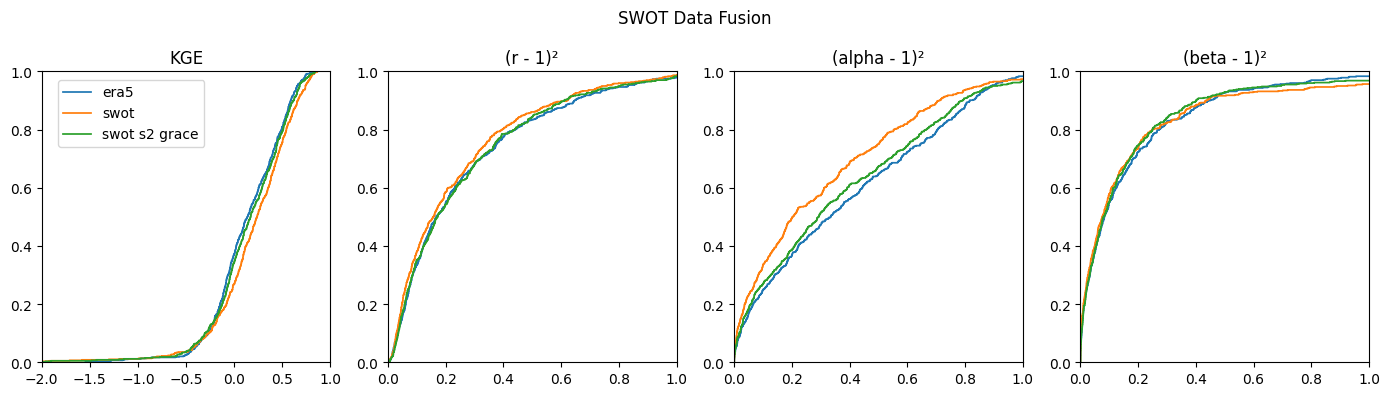

In [5]:
plt.close('all')

target = 'discharge'
num_models = len(exps)

metric_names = {
    # 'MSESS': 'MSESS',
    # 'nse_prob': 'NSE prob',
    'KGE': 'KGE',
    'corr': '(r - 1)²',
    'alpha': '(alpha - 1)²',
    'beta': '(beta - 1)²'
}

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes = axes.flatten()

for ax, (name, title) in zip(axes, metric_names.items()):
    for exp_name, results, bulk_metrics, basin_metrics in exps:
        x = np.array(basin_metrics[target][name], dtype=float)
        
        if name in ['alpha', 'beta', 'corr']:
            x = (x-1)**2
        
        x = x[~np.isnan(x)]
        if len(x)<10:
            continue
        ax.ecdf(x, linewidth=1.25, label=exp_name)
    
    ax.set_title(f"{title}")

axes[0].set_xlim([-2, 1])
axes[1].set_xlim([0, 1])
axes[2].set_xlim([0, 1])
axes[3].set_xlim([0, 1])

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', bbox_to_anchor=(0.04, 0.82))

# fig.subplots_adjust(left=0.1, right=0.95, bottom=0.2, top=0.95, wspace=0.3, hspace=0.4)
plt.suptitle('SWOT Data Fusion')
plt.tight_layout()
plt.show()

# fig.savefig(fig_dir / f"KGE_decomp.png", dpi=300)

In [34]:
exps[0][1]

pred                       obs
                                         discharge discharge_std   discharge
basin         subbasin      date                                            
USGS-07374000 ECCC-11AA025  2023-04-01    5.262514      3.636722    2.220000
              USGS-03017500 2023-04-01   22.038839     21.931913   37.944572
              USGS-03024000 2023-04-01  144.156418     93.887100  142.433746
              USGS-03029500 2023-04-01   75.249046     49.303654  108.453514
              USGS-03030500 2023-04-01   75.084480     45.956039  124.027786
...                                            ...           ...         ...
              USGS-07249455 2025-12-31  524.467041    216.715942  223.986298
              USGS-07263115 2025-12-31   15.446615      9.723208    6.682775
              USGS-07276000 2025-12-31    2.660904      3.315521    1.968021
              USGS-07289730 2025-12-31   10.801863     13.490446    8.240201
              USGS-07295000 2025-12-31    2.359367      3.205216    1.209129

[429103 rows x 3 columns]

In [35]:
import xarray as xr

basin_mask = (subbasins['outlet_id'] == 'USGS-07374000')
test_sub_mask = subbasins.index.isin(results.index.get_level_values('subbasin').unique())
basin_gauges = subbasins[basin_mask & test_sub_mask].index
basin_ds = xr.open_zarr("/scratch4/workspace/tlanghorst_umass_edu-swot-ml-zarr/zbs_batched/USGS-07374000")
gauge_ds = basin_ds.sel(subbasin=basin_gauges)


# ds = ds.sel(subbasin=reach_id, date=slice(start_date, end_date))
# has_swot_obs = ~np.isnan(ds['d_wse_river'].to_numpy())

In [36]:
gauge_swot_count = (~gauge_ds['d_wse_river'].to_dataframe().isna()).groupby('subbasin').apply(np.sum, axis=0)
gauge_swot_count.sort_values(by='d_wse_river', inplace=True)

In [37]:
gauge_swot_count

,d_wse_river
subbasin,
ECCC-11AA025,0
USGS-06354050,0
USGS-06354000,0
USGS-06351200,0
USGS-06349000,0
...,...
USGS-06185500,66
USGS-06770200,69
USGS-06438500,76


(-0.5, 0.5)

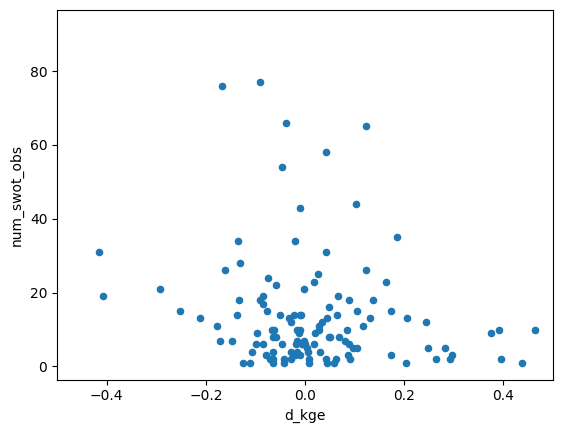

In [38]:
metric = 'NSE'

joined_kge = exps[0][3][target][metric].rename('era5').to_frame().join(exps[1][3][target][metric].rename('swot'))
joined_kge['d_kge'] = joined_kge['swot'] - joined_kge['era5'] 
joined_kge = joined_kge.join(gauge_swot_count.rename(columns={'d_wse_river':'num_swot_obs'}))
joined_kge = joined_kge[joined_kge['num_swot_obs']>0]

joined_kge.plot.scatter('d_kge','num_swot_obs')
plt.xlim([-0.5, 0.5])

In [39]:
kge = exps[1][3][target]['MSESS'].dropna().sort_values(ascending=False)

kge[kge>0]

Series([], Name: MSESS, dtype: object)

In [28]:
exps[1][3][target]

Metric,num_obs,R2,r,NSE,sigE,rRMSE,MAPE,nBias,RE,RB,Agreement,KGE,corr,alpha,beta,nse_prob,MSESS
ECCC-11AA025,205,-1.543315,0.360588,-1.543315,0.773224,70.783579,1.385443,0.999006,110.694432,99.900627,0.116719,-0.175413,0.185763,0.904589,1.842325,NaN,NaN
USGS-03017500,962,0.655358,0.883215,0.655358,0.343208,93.184632,0.485998,0.020993,41.439331,2.099311,0.752613,0.55397,0.854093,0.6138,0.831172,NaN,NaN
USGS-03024000,990,0.70698,0.85176,0.70698,0.400856,56.367499,0.708164,0.276416,52.469218,27.641404,0.83341,0.794824,0.841516,0.870992,1.018351,NaN,NaN
USGS-03029500,1006,0.683467,0.912055,0.683467,0.273409,82.0575,0.305051,-0.044807,26.843596,-4.69085,0.779495,0.600468,0.859107,0.651232,0.865332,NaN,NaN
USGS-03030500,1006,0.679702,0.88397,0.679702,0.331264,83.304894,0.390747,-0.009257,32.33726,-0.934339,0.77882,0.617291,0.848431,0.664661,0.894925,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
USGS-07274000,648,0.418355,0.751448,0.418355,0.485353,167.313433,0.911762,0.538421,84.563541,53.841949,0.55115,0.413601,0.661958,0.539469,0.867702,NaN,NaN
USGS-07276000,753,0.554318,0.807147,0.554318,0.424896,155.469215,0.594018,0.342574,50.766373,34.25746,0.678854,0.516987,0.764616,0.616064,0.82539,NaN,NaN
USGS-07288000,343,-0.00622,0.463878,-0.00622,0.687141,100.14559,1.272375,0.9337,117.835879,93.37002,0.217447,0.106935,0.272483,0.513055,1.17655,NaN,NaN
USGS-07289730,1006,0.333917,0.88149,0.333917,0.556591,217.70947,0.688858,0.226492,75.737834,22.648871,0.450449,0.214,0.699401,0.390309,0.605395,NaN,NaN


In [12]:
joined_kge['d_kge'].sort_values()

NameError: name 'joined_kge' is not defined

0

10
era5: 0.18
era5 mlp: 0.41
swot: -0.12
swot large: 0.18
swot mlp: -0.09


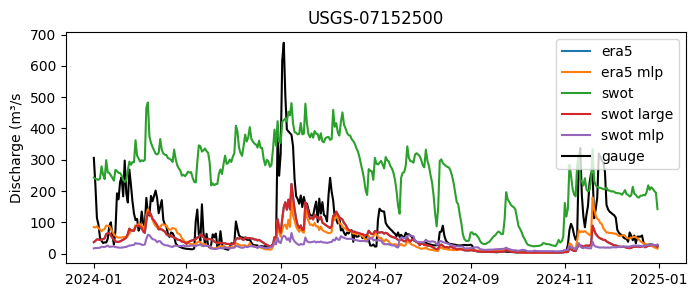

In [40]:
import xarray as xr

reach_id = 'USGS-07152500'
start_date = "2024-01-01"
end_date = "2024-12-31"
metric = 'KGE'

# Horrible hackishness
basin_id = subbasins.loc[reach_id]['outlet_id']
basin_ds = xr.open_zarr(f"/scratch4/workspace/tlanghorst_umass_edu-swot-ml-zarr/zbs_batched/{basin_id}")
subbasin_ds = basin_ds.sel(subbasin=reach_id, date=slice(start_date, end_date))
has_swot_obs = ~np.isnan(subbasin_ds['d_wse_river'].to_numpy())

print(np.sum(has_swot_obs))

fig, ax = plt.subplots(1, 1, figsize=(8, 3))

for exp_name, results, bulk_metrics, basin_metrics in exps: 
    xs = results.xs(reach_id, level='subbasin').sort_index()
    xs = xs.droplevel(0,0)
    xs = xs.loc[start_date:end_date]

    x = xs.index
    y = xs['pred'][target]
    plt.plot(x, y, label=exp_name)
    
    print(f"{exp_name}: {basin_metrics.loc[reach_id][target][metric]:0.2f}")
    
ax.plot(xs.index, xs['obs'][target], color='black', zorder=0, label='gauge')

plt.legend()
plt.title(reach_id)
plt.ylabel("Discharge (m³/s")
plt.show()
# fig.savefig(fig_dir / f"timeseries_{reach_id}.png", dpi=300)

In [41]:
gauge_swot_count = gauge_swot_count.sort_values(by='d_wse_river', ascending=False)

In [42]:

reach_ds = ds.sel(subbasin=reach_id, date=slice(start_date, end_date))
date = reach_ds.date.values
d_wse = reach_ds['d_wse_river'].values
# plt.scatter(date,d_wse)

NameError: name 'ds' is not defined

In [43]:
kge = exps[1][3][target]['KGE'].dropna().sort_values(ascending=False)

# kge[kge>0]

((0.12156862745098039, 0.4666666666666667, 0.7058823529411765),
 (1.0, 0.4980392156862745, 0.054901960784313725),
 (0.17254901960784313, 0.6274509803921569, 0.17254901960784313),
 (0.8392156862745098, 0.15294117647058825, 0.1568627450980392),
 (0.5803921568627451, 0.403921568627451, 0.7411764705882353),
 (0.5490196078431373, 0.33725490196078434, 0.29411764705882354),
 (0.8901960784313725, 0.4666666666666667, 0.7607843137254902),
 (0.4980392156862745, 0.4980392156862745, 0.4980392156862745),
 (0.7372549019607844, 0.7411764705882353, 0.13333333333333333),
 (0.09019607843137255, 0.7450980392156863, 0.8117647058823529))

USGS-06329500: 92
era5: -0.35
era5 mlp: -0.01
swot: 0.38
swot large: -0.35
swot mlp: -0.20


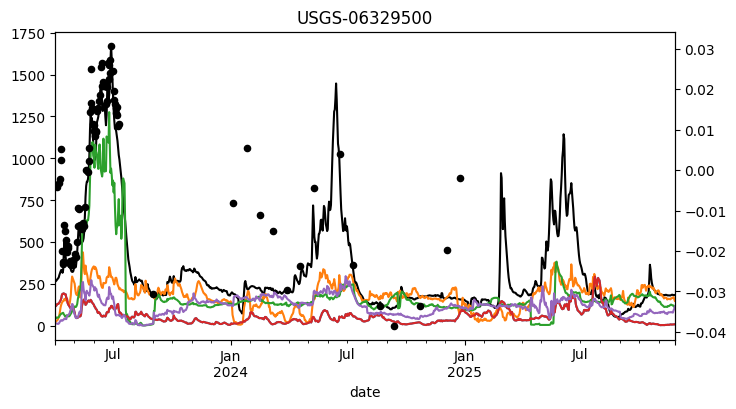

USGS-06799000: 77
era5: 0.25
era5 mlp: 0.28
swot: -0.97
swot large: 0.25
swot mlp: -0.71


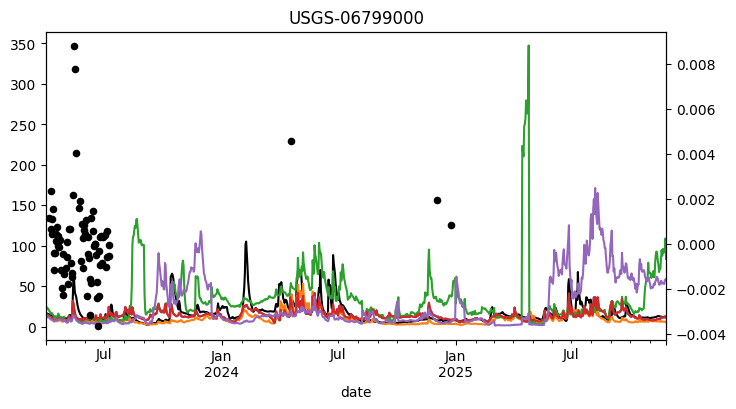

USGS-06438500: 76
era5: 0.10
era5 mlp: -0.05
swot: 0.30
swot large: 0.10
swot mlp: -0.05


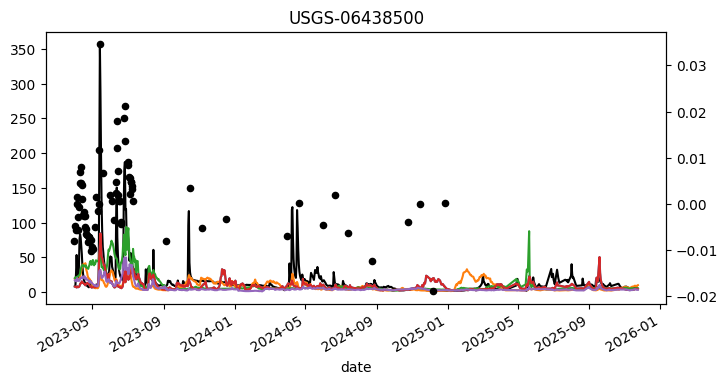

USGS-06770200: 69
era5: -0.66
era5 mlp: 0.47
swot: -2.16
swot large: -0.66
swot mlp: 0.16


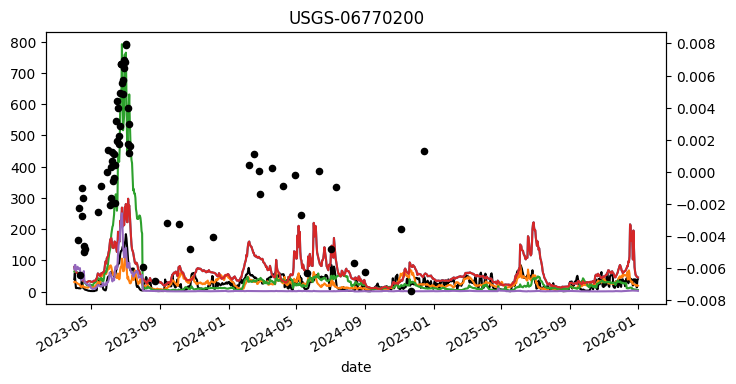

USGS-06185500: 66
era5: 0.35
era5 mlp: 0.26
swot: 0.32
swot large: 0.35
swot mlp: -0.11


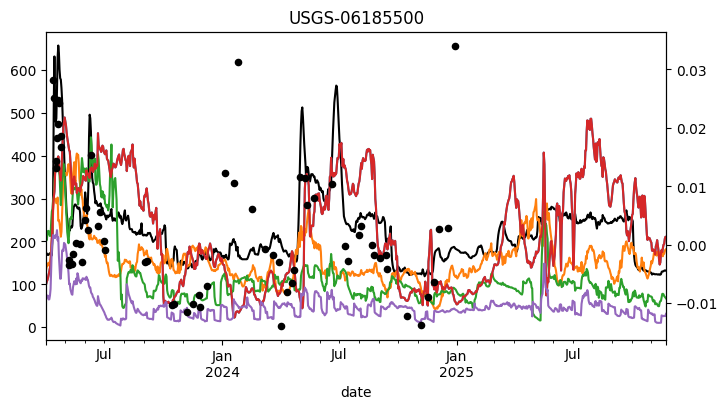

USGS-06287800: 65
era5: 0.36
era5 mlp: 0.51
swot: 0.57
swot large: 0.36
swot mlp: 0.69


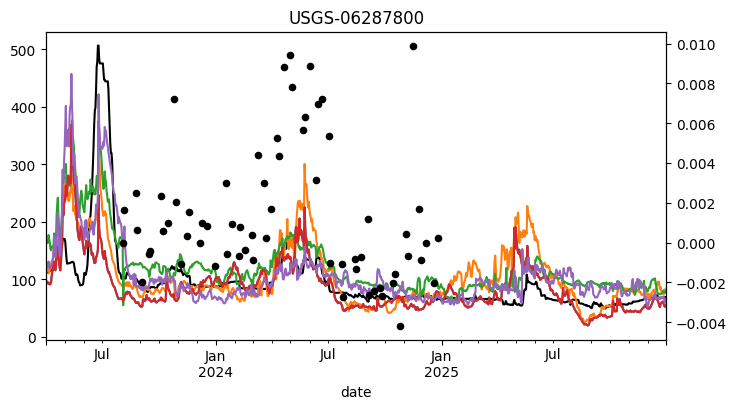

USGS-06777495: 60
era5: -1.95
era5 mlp: 0.12
swot: -0.67
swot large: -1.95
swot mlp: -7.00


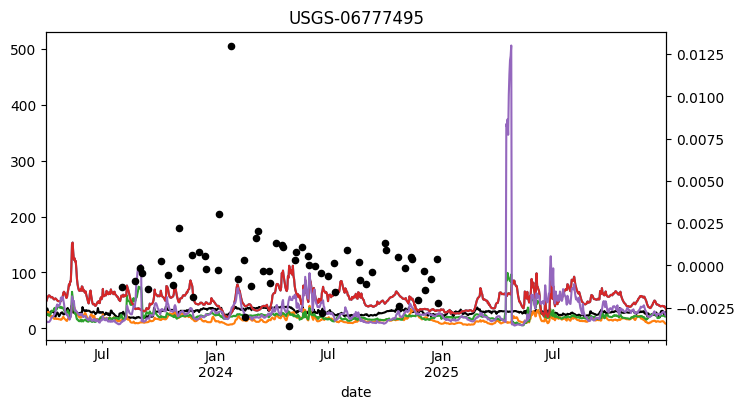

USGS-06336000: 58
era5: -0.08
era5 mlp: 0.24
swot: 0.31
swot large: -0.08
swot mlp: -0.62


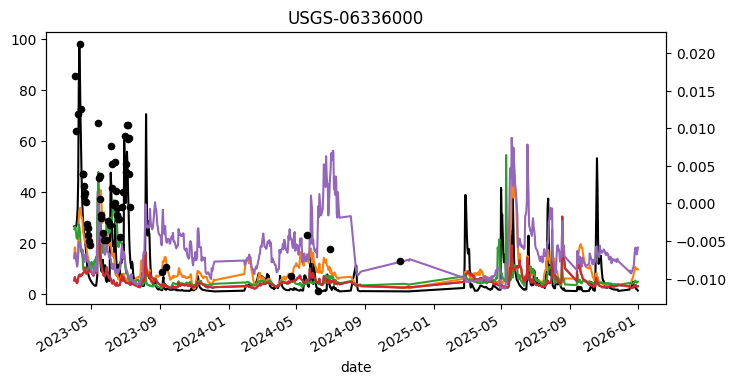

USGS-03294500: 54
era5: -0.02
era5 mlp: 0.62
swot: 0.10
swot large: -0.02
swot mlp: 0.10


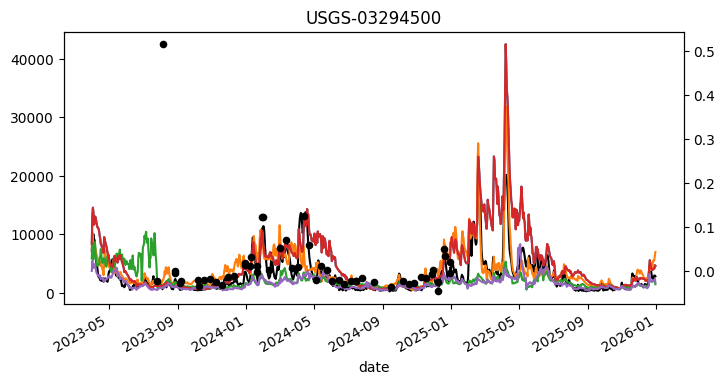

USGS-06446500: 54
era5: -0.18
era5 mlp: -0.28
swot: -0.05
swot large: -0.18
swot mlp: -0.29


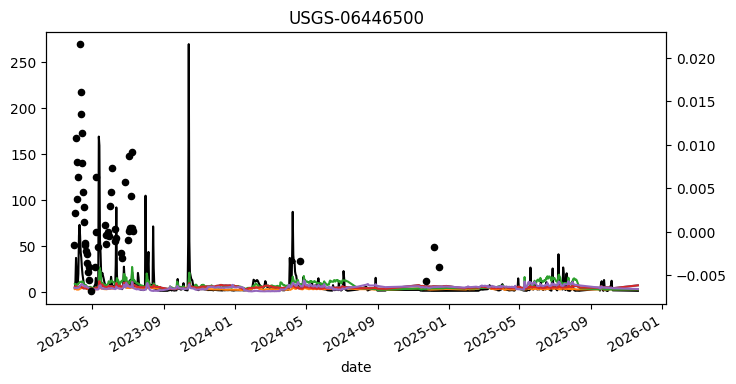

USGS-05355250: 53
era5: -0.62
era5 mlp: 0.52
swot: 0.15
swot large: -0.62
swot mlp: 0.24


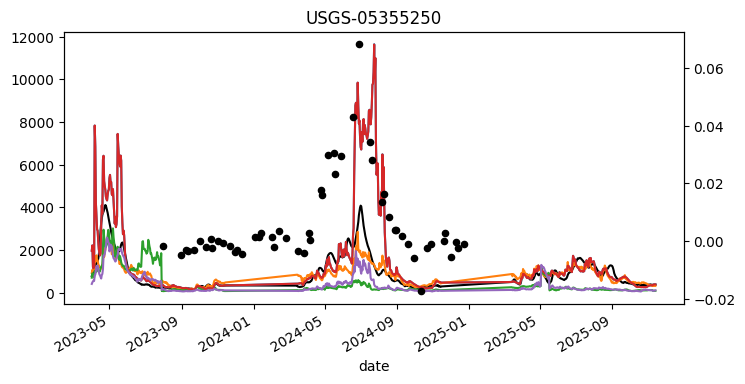

USGS-06040000: 44
era5: 0.31
era5 mlp: 0.28
swot: 0.01
swot large: 0.31
swot mlp: 0.02


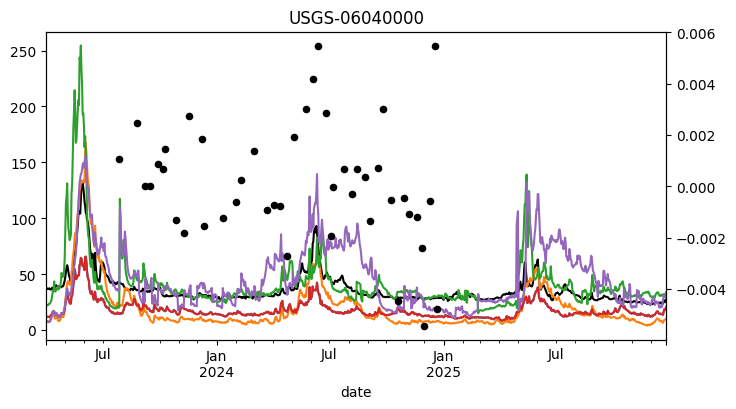

USGS-03292494: 43
era5: -0.16
era5 mlp: -0.29
swot: -0.22
swot large: -0.16
swot mlp: -0.39


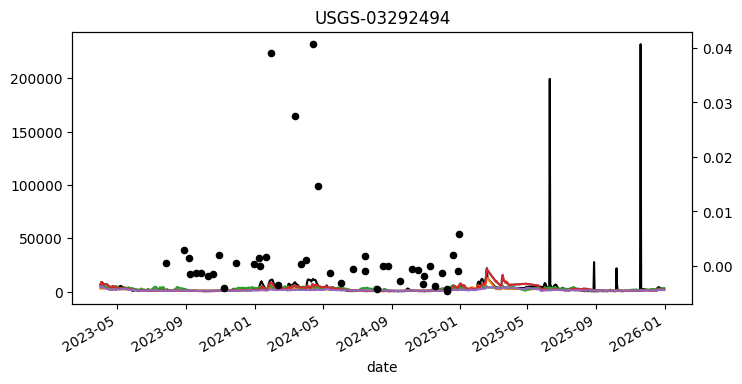

USGS-06801000: 41
era5: 0.58
era5 mlp: 0.27
swot: -0.31
swot large: 0.58
swot mlp: -1.29


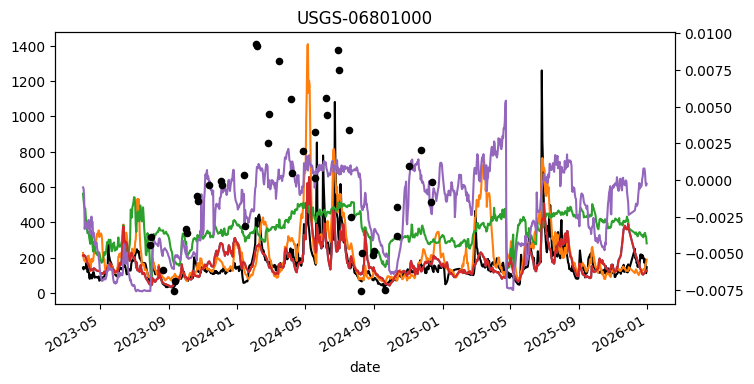

USGS-05344490: 35
era5: 0.37
era5 mlp: 0.63
swot: -0.82
swot large: 0.37
swot mlp: -1.19


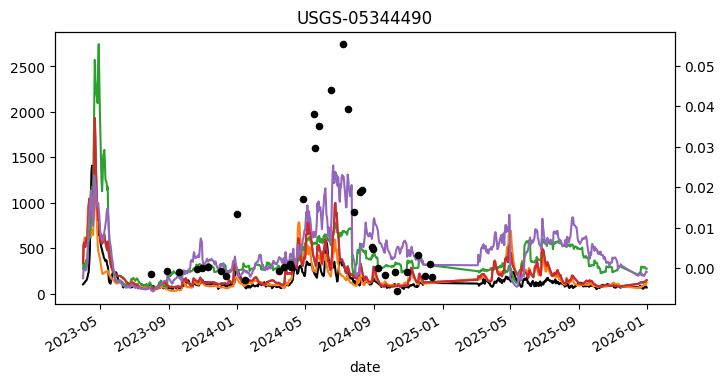

USGS-06324500: 34
era5: 0.51
era5 mlp: 0.58
swot: 0.46
swot large: 0.51
swot mlp: 0.33


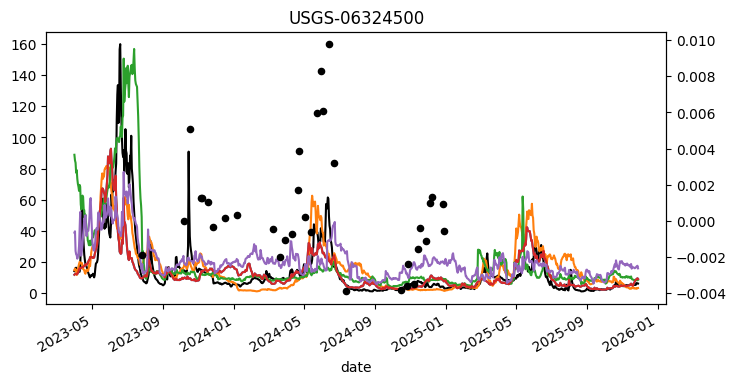

USGS-05369500: 34
era5: 0.80
era5 mlp: 0.64
swot: 0.17
swot large: 0.80
swot mlp: -0.18


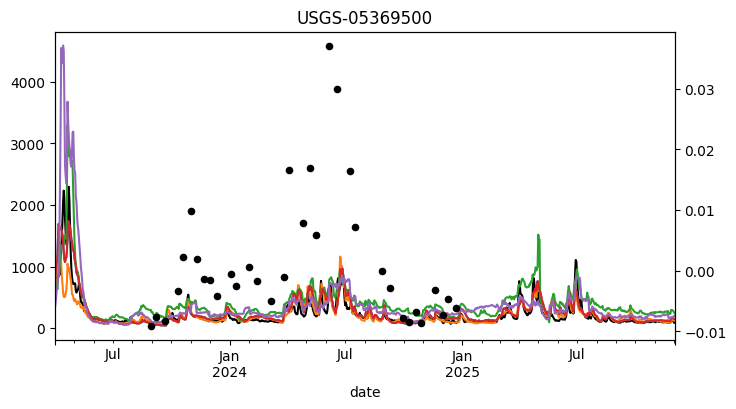

USGS-05344500: 32
era5: -0.32
era5 mlp: 0.57
swot: -0.47
swot large: -0.32
swot mlp: 0.05


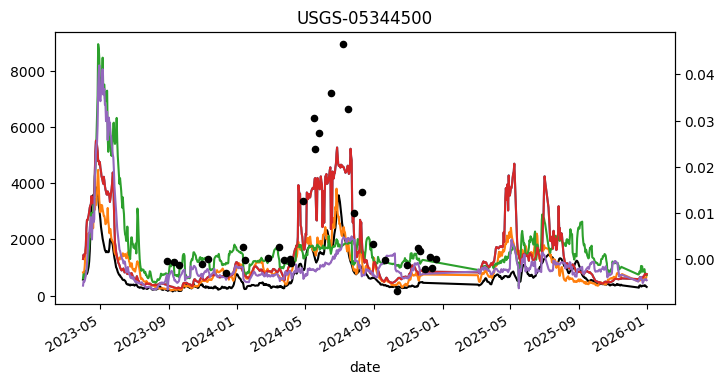

USGS-07060500: 31
era5: 0.34
era5 mlp: 0.30
swot: 0.55
swot large: 0.34
swot mlp: 0.48


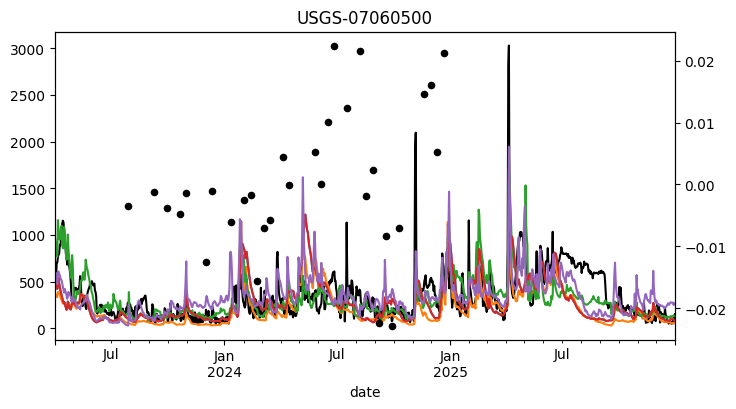

USGS-07032000: 31
era5: -0.30
era5 mlp: -0.25
swot: -0.27
swot large: -0.30
swot mlp: -0.52


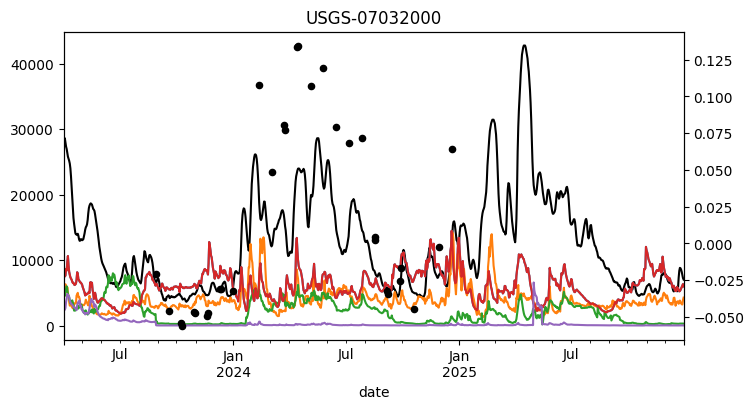

In [57]:
metric = 'KGE'
target='discharge'
start_date = '2023-01-01'
end_date = '2025-12-31'
# colors = ['tab:blue','tab:orange']
colors = plt.get_cmap('tab10').colors

zbs_root = Path("/scratch4/workspace/tlanghorst_umass_edu-swot-ml-zarr/zbs_batched/")

for reach_id, row in joined_kge.sort_values('num_swot_obs', ascending=False).iloc[0:20].iterrows():

    basin_id = subbasins.loc[reach_id]['outlet_id']
    basin_ds = xr.open_zarr(zbs_root / basin_id)
    
    fig, ax = plt.subplots(1, 1, figsize=(8, 4))

    print(f"{reach_id}: {row['num_swot_obs']:.0f}")

    for (exp_name, results, bulk_metrics, basin_metrics), color in zip(exps, colors): 
        x = results.xs(reach_id, level='subbasin').sort_index()
        x = x.droplevel(0,0)
        x = x.loc[start_date:end_date]
        x['pred'][target].plot(ax=ax, color = color, label=exp_name)
        print(f"{exp_name}: {basin_metrics.loc[reach_id][target][metric]:0.2f}")

    x['obs'][target].plot(color='black', ax=ax, zorder=0, label='gauge')

    ax2 = ax.twinx()  # shares x axis but has its own y axis
    
    reach_ds = basin_ds.sel(subbasin=reach_id, date=slice(start_date, end_date))
    date = reach_ds.date.values
    d_wse = reach_ds['d_wse_river'].values / 50
    ax2.scatter(date, d_wse, color='black', s=20, zorder=10, label='d_wse')
        
    
    # plt.legend()
    plt.title(reach_id)
    plt.show()

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

exp_idx = 1
name = exps[exp_idx][0]

x = exps[exp_idx][1]['obs'][target]
y = exps[exp_idx][1]['pred'][target]
positive_mask = (x > 0) & (y > 0)
x = x[positive_mask]
y = y[positive_mask]

min_val = 5E-2
max_val = 5E4
log_min = np.log10(min_val)
log_max = np.log10(max_val)

hb = ax.hexbin(x, y, gridsize=(50,50), bins='log', mincnt=5,
            linewidth=0.1,
            extent=(log_min, log_max, log_min, log_max),
            xscale='log', yscale='log')
plt.colorbar(hb, shrink=0.6, aspect=10, anchor=(0,0.5))

# Add a 1:1 line over the min and max of x and y
ax.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1.5)

# Setting axes to be square and equal range
ax.axis('square')
ax.set_xlim(min_val, max_val)
ax.set_ylim(min_val, max_val)
ax.set_title(f"{name}: Discharge (n {len(x):,})")
ax.set_xlabel(f'Observed [m3/s]')
ax.set_ylabel(f'Predicted [m3/s]')
plt.show()

# fig.savefig(fig_dir / f"{name}_bulk_scatterplots.png", dpi=300)